# Assignment 2: Text Classification, Word2Vec & Sentence Embeddings (100 Points)

**Course Alignment:** Weeks 2, 3 & 4 (Supervised Classification, Word2Vec, PyTorch BiLSTM & SBERT Embeddings)  
**Submission:** Submit modular Python notebook (`.ipynb`) or script (`.py`) along with an exported HTML report.  
**Honor Code:** Work independently. Selective LLM assistance is permitted for debugging and iterative improvement.


All code lives in the `assignment2/` package. This notebook imports it and runs it. Everything runs in the `ml_hw` conda environment.

| Module | Purpose |
|---|---|
| `config.py` | seed, paths, labels, model lists |
| `data.py` | download AG News (Kaggle), clean text, load the scraped articles and their hand labels |
| `eda.py` | class balance, lengths, top words, word clouds |
| `classic.py` | TF-IDF and Word2Vec features, 5 ML pipelines, metrics and confusion matrix |
| `embeddings.py` | sentence-encoder features (cached to `assignment2/cache/`), classifier comparison |
| `similarity.py` | headline heatmaps, same-story checks |
| `vectordb.py` | uint8 / binary quantization, Qdrant collection, search metrics |
| `search_app.py` | Streamlit search app on top of the Qdrant collection |
| `scraped_labels.csv` | my labels (1-4) for the 50 articles scraped in Assignment 1 |

In [1]:
%load_ext autoreload
%autoreload 2
import os, sys, warnings
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.abspath("."))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import transformers
transformers.logging.set_verbosity_error()
pd.set_option("display.max_colwidth", 120)

from assignment2 import config, data, eda, classic, embeddings, similarity, vectordb
print("python", sys.version.split()[0], "| env:", sys.prefix, "| device:", embeddings.DEVICE)

python 3.11.11 | env: /opt/anaconda3/envs/ml_hw | device: mps


##  2.1 Paper Review (10):  

Select and review any one technical paper from the list of papers provide in Group2.

**Paper:** _<title, authors, year>_

_TODO: write the review here (summary, method, results, strengths, weaknesses, how it relates to this assignment)._

##  2.2 - Basic News Classifier (20)

1. Download and clean the [news_ag](https://www.kaggle.com/datasets/amananandrai/ag-news-classification-dataset) dataset.
2. Perform Exploratory data analysis (EDA) such as showing class distributions, word clouds for various classes, etc.
3. Perform data cleaning if necessary - removing stop words, special characters, lower casing, etc.
4. Use an appropriate encoding - TF-IDF, CountVectorizer, Word2Vec.
5. Build a pipeline and train multiple (2-3) classifiers using Machine Learning models such as Logistic Regression, RandomForest, etc.
6. Compare classifiers and pick the best one based on test evaluation scores
7. Provide test classfication accuracy metrics such as Accuracy, F1, and Confusion matrix.
8. Manually label your scrapped news dataset with categories like in [news_ag](https://www.kaggle.com/datasets/amananandrai/ag-news-classification-dataset): 1-World, 2-Sports, 3-Business, 4-Sci/Tech
9. Use the trained classifier to make predictions on your scraped news dataset and report the evaluation metrics.

### 1. Download and clean
AG News is downloaded with `kagglehub`. Cleaning removes exact duplicates, HTML entities, `#36;`-style codes, backslashes and bylines like `Reuters - `. Two text columns are kept: `text` (light clean, for sentence encoders) and `clean` (lowercase, letters only, no stop words, for TF-IDF and Word2Vec).

In [2]:
train, test = data.load_ag_news()
print(f"train {train.shape}, test {test.shape}")
train[["label", "title", "description", "text", "clean"]].head(3)

train (120000, 5), test (7600, 5)


,label,title,description,text,clean
0,3,Wall St. Bears Claw Back Into the Black (Reuters),"Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again.","Wall St. Bears Claw Back Into the Black (Reuters). Short-sellers, Wall Street's dwindling band of ultra-cynics, are ...",wall st bears claw black short sellers wall street dwindling band ultra cynics seeing green
1,3,Carlyle Looks Toward Commercial Aerospace (Reuters),"Reuters - Private investment firm Carlyle Group,\which has a reputation for making well-timed and occasionally\contr...","Carlyle Looks Toward Commercial Aerospace (Reuters). Private investment firm Carlyle Group, which has a reputation f...",carlyle looks commercial aerospace private investment firm carlyle group reputation making timed occasionally contro...
2,3,Oil and Economy Cloud Stocks' Outlook (Reuters),Reuters - Soaring crude prices plus worries\about the economy and the outlook for earnings are expected to\hang over...,Oil and Economy Cloud Stocks' Outlook (Reuters). Soaring crude prices plus worries about the economy and the outlook...,oil economy cloud stocks outlook soaring crude prices plus worries economy outlook earnings expected hang stock mark...


### 2. Exploratory data analysis

,train,test
label,,
Business,30000,1900
Sci/Tech,30000,1900
Sports,30000,1900
World,30000,1900


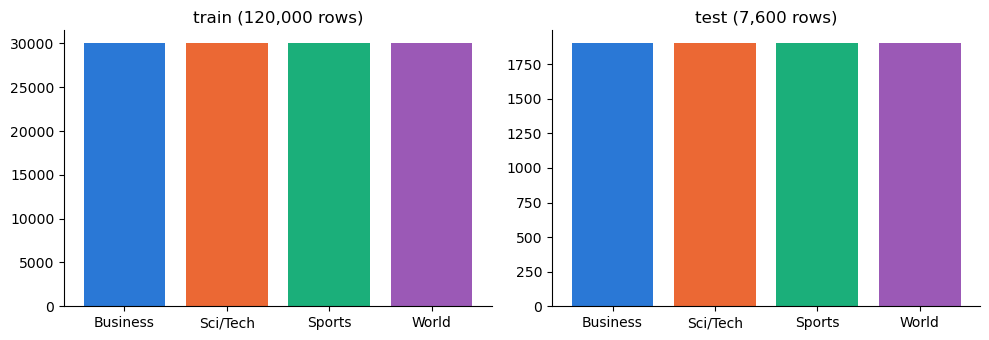

In [3]:
eda.class_distribution(train, test)

words                                           clean_words        \
            count  mean   std  min   25%   50%   75%    max       count  mean   
label                                                                           
Business  30000.0  36.9   7.8  7.0  32.0  37.0  42.0  134.0     30000.0  22.3   
Sci/Tech  30000.0  36.8  12.4  8.0  30.0  36.0  42.0  177.0     30000.0  22.3   
Sports    30000.0  37.3   8.8  4.0  31.0  36.0  42.0  151.0     30000.0  21.4   
World     30000.0  38.3  10.2  9.0  32.0  38.0  43.0  145.0     30000.0  22.9   

                                            
          std  min   25%   50%   75%   max  
label                                       
Business  4.7  2.0  19.0  22.0  25.0  87.0  
Sci/Tech  6.8  5.0  18.0  22.0  25.0  88.0  
Sports    5.1  1.0  18.0  21.0  24.0  74.0  
World     6.0  6.0  19.0  23.0  26.0  77.0

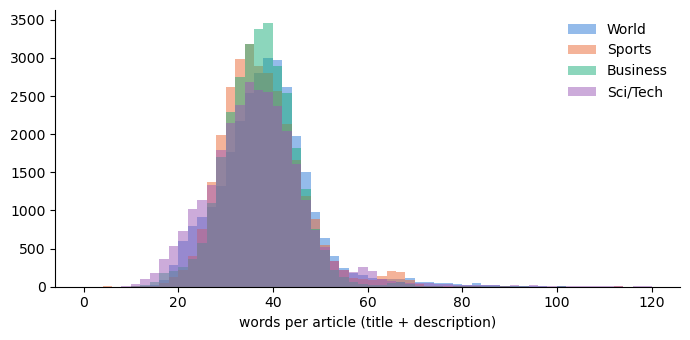

In [4]:
eda.length_stats(train)

In [5]:
eda.top_words(train)

,World,Sports,Business,Sci/Tech
0,iraq,game,oil,microsoft
1,president,season,company,software
2,minister,team,prices,internet
3,killed,win,percent,company
4,people,night,year,space
5,government,world,corp,search
6,bush,cup,profit,computer
7,iraqi,league,million,service
8,prime,year,quarter,security
9,security,victory,sales,music


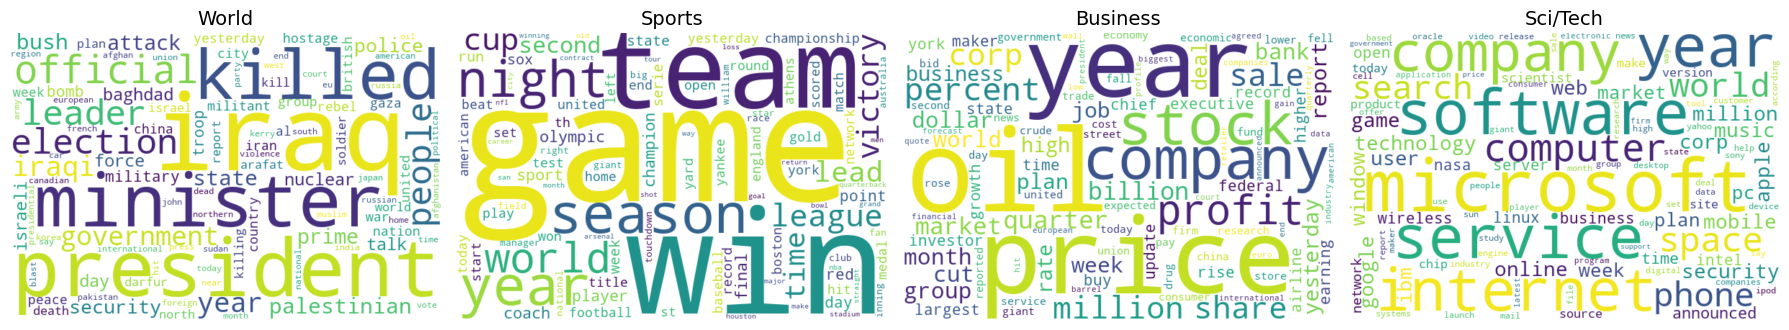

In [6]:
eda.word_clouds(train)

**EDA notes**
- The 4 classes are perfectly balanced, so accuracy is a fair metric.
- Articles are short: about 37 words (23 after cleaning), similar for every class.
- Each class has clear keywords (World: iraq, president; Sports: game, team; Business: oil, prices; Sci/Tech: microsoft, software). So simple word-count features should work well.

### 3-5. Cleaning, encodings and pipelines
Two encodings are tested: TF-IDF (unigrams + bigrams) and Word2Vec trained on the AG News training text (mean of word vectors). Each encoding goes into a scikit-learn `Pipeline` with a classifier, so the vectorizer is fit on the training split only.

In [7]:
pipelines = classic.make_pipelines()
clf_table, fitted = classic.train_all(pipelines, train["clean"], train["label"], test["clean"], test["label"])
clf_table.sort_values("accuracy", ascending=False)

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


,accuracy,macro_F1,weighted_F1,fit_seconds
model,,,,
TF-IDF + LinearSVC,0.9208,0.9206,0.9206,4.9449
TF-IDF + LogisticRegression,0.9167,0.9166,0.9166,14.6199
TF-IDF + ComplementNB,0.9109,0.9105,0.9105,4.1567
Word2Vec + RandomForest,0.8930,0.8929,0.8929,63.1106
Word2Vec + LogisticRegression,0.8849,0.8847,0.8847,14.9372


### 6-7. Pick the best model and report test metrics

Best model: TF-IDF + LinearSVC
              precision    recall  f1-score   support

       World      0.941     0.901     0.920      1900
      Sports      0.958     0.984     0.971      1900
    Business      0.892     0.884     0.888      1900
    Sci/Tech      0.893     0.914     0.903      1900

    accuracy                          0.921      7600
   macro avg      0.921     0.921     0.921      7600
weighted avg      0.921     0.921     0.921      7600



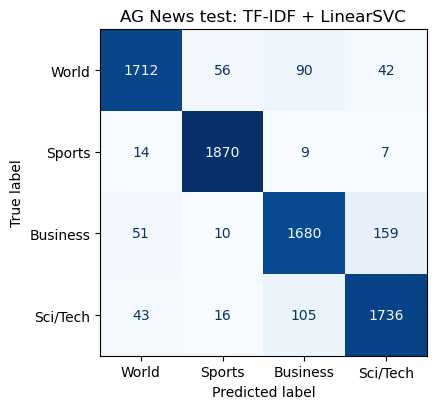

In [8]:
best_name = clf_table["macro_F1"].idxmax()
best = fitted[best_name]
print("Best model:", best_name)
classic.report(test["label"], best.predict(test["clean"]), title=f"AG News test: {best_name}")

### 8-9. Hand-labelled scraped news
I labelled the 50 articles scraped in Assignment 1 (`assignment2/scraped_labels.csv`). Each article is cut to its headline plus first sentence, the same format as AG News (title + short description), which the model was trained on.

In [9]:
scraped = data.load_scraped()
print(scraped["label"].map(config.LABEL_NAMES).value_counts().to_string())
scraped[["source", "title", "label"]].assign(category=scraped["label"].map(config.LABEL_NAMES)).head(10)

label
World       43
Sci/Tech     6
Sports       1


,source,title,label,category
0,BBC,Curfew imposed in parts of central Paris and other cities after rioting across France,1,World
1,BBC,"Ukrainians dying because US restricting intelligence sharing, Zelensky adviser tells BBC",1,World
2,BBC,Shakahola cult leader Paul Mackenzie guilty of 191 murder charges in Kenya,1,World
3,BBC,Tennis star Svitolina says emotional toll of Ukraine war led to Monfils separation,2,Sports
4,BBC,Five ways El Niño is affecting the weather around the world,4,Sci/Tech
5,BBC,"Ex-OpenAI worker accused of planting device had Saudi support, says court filing",4,Sci/Tech
6,BBC,Robert Kabera: Critic of Rwandan President Paul Kagame found beheaded in Uganda,1,World
7,BBC,"Houthi missile strike on Yemen camp kills 50 security recruits, authorities say",1,World
8,BBC,US airman dies as daredevil descent goes wrong before Texas college football game,1,World
9,BBC,Obama blasts Trump administration probe of congresswoman Ilhan Omar as 'so appalling',1,World


{'accuracy': 0.78, 'macro_F1': 0.40749756572541385, 'weighted_F1': 0.8325608568646543}
              precision    recall  f1-score   support

       World      0.944     0.791     0.861        43
      Sports      0.000     0.000     0.000         1
    Business      0.000     0.000     0.000         0
    Sci/Tech      0.714     0.833     0.769         6

    accuracy                          0.780        50
   macro avg      0.415     0.406     0.407        50
weighted avg      0.898     0.780     0.833        50



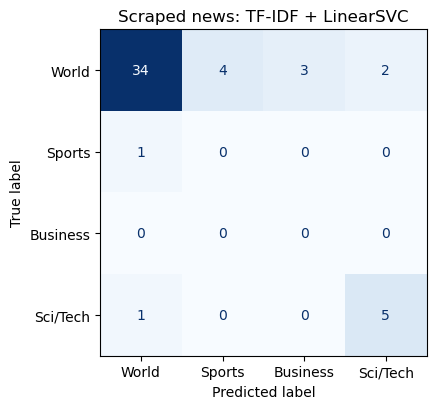

In [10]:
pred_scraped = best.predict(scraped["clean"])
print(classic.scores(scraped["label"], pred_scraped))
classic.report(scraped["label"], pred_scraped, title=f"Scraped news: {best_name}")

In [11]:
wrong = scraped.assign(true=scraped["label"].map(config.LABEL_NAMES),
                       predicted=pd.Series(pred_scraped).map(config.LABEL_NAMES))
wrong.loc[wrong["true"] != wrong["predicted"], ["source", "title", "true", "predicted"]]

,source,title,true,predicted
3,BBC,Tennis star Svitolina says emotional toll of Ukraine war led to Monfils separation,Sports,World
8,BBC,US airman dies as daredevil descent goes wrong before Texas college football game,World,Sports
9,BBC,Obama blasts Trump administration probe of congresswoman Ilhan Omar as 'so appalling',World,Business
10,NPR,Judge chastises Trump administration plan to push ahead overhaul of DC golf course,World,Business
14,NPR,The real reason it's going to take a while to know who won in some midterm races,World,Sports
22,Guardian,"Hilarious quips and ‘100,000-volt’ energy: the hypemen (and women) redefining Afrobeats music",World,Sci/Tech
35,Al Jazeera,"Trump signs order launching women’s health division at NIH, White House",World,Business
39,CBS News,U.S. service member dies after rappelling incident at UT San Antonio football stadium,World,Sports
44,CBS News,"Transcript: Rep. Mike Turner on ""Face the Nation with Margaret Brennan,"" Oct. 18, 2026",World,Sports
46,CBS News,"As AI dominates conversations, here are key terms to know",Sci/Tech,World


**Results on the scraped news**
- Accuracy is 0.78 (weighted F1 0.83), down from 0.92 on AG News.
- The set is mostly World (43 of 50), with no Business, so weighted F1 is a better summary than macro F1 (0.41).
- Most errors are US politics stories. AG News is from 2004, so the model has not seen words like "Trump", "midterm" or "DOJ".
- A few articles fit no class (music, a TV transcript), and some labels are judgement calls.

## 2.3 - Advanced Embeddings Classifier (20)

The goal is to improve our news classifier using advanced SentenceEncoders. Modular code with functions will be very helpful in this exercise. Provide code and screenshots for the for news articles that were scraped earlier:

Modify your news classifier to use various embedding models.

1. Explore [embedding schemes](https://huggingface.co/spaces/mteb/leaderboard) best for **classification** from the HuggingFace leader board.
2. Generate embeddings for news headlines using various encoders. Be conscious of the memory and size of these models and your compute limitations.
3. Compare and plot performance of various embeddings in terms of classfication metrics.
4. Research your choosen embedding scheme and write a few sentences on how it has been generated.

### 1. Encoders chosen from the MTEB leaderboard
I filtered the MTEB leaderboard (English, Classification tab) to models under ~150M parameters, so they run on a laptop GPU (Apple MPS).

| Model | Params | Dim | Why |
|---|---|---|---|
| all-MiniLM-L6-v2 | 23M | 384 | common small baseline |
| bge-small-en-v1.5 | 33M | 384 | strong small model on MTEB |
| gte-small | 33M | 384 | strong small model on MTEB classification |
| e5-small-v2 | 33M | 384 | uses a `query: ` prefix for classification |
| bge-base-en-v1.5 | 109M | 768 | larger version of bge, to see if size helps |

### 2-3. Embeddings and classification metrics
Each model encodes `title. description`. Logistic Regression is trained on a balanced 20,000-article subsample of the train split (5,000 per class) and tested on the full AG News test split and the 50 scraped articles. The best TF-IDF model is refit on the same 20,000 articles so the comparison is fair. Embeddings are cached in `assignment2/cache/`.

In [12]:
emb_train = data.balanced_subsample(train, config.N_EMB_TRAIN)
emb_table, emb_preds = embeddings.compare_encoders(config.CLASSIFICATION_MODELS, emb_train, test, scraped)

from sklearn.base import clone
tfidf_small = clone(best).fit(emb_train["clean"], emb_train["label"])
t, s = (classic.scores(df["label"], tfidf_small.predict(df["clean"])) for df in (test, scraped))
emb_table.loc[f"TF-IDF baseline ({best_name.split(' + ')[1]}, 20k)"] = {
    "test_accuracy": t["accuracy"], "test_macro_F1": t["macro_F1"],
    "scraped_accuracy": s["accuracy"], "scraped_weighted_F1": s["weighted_F1"]}
emb_table.loc[f"TF-IDF full ({best_name.split(' + ')[1]}, 120k)"] = {
    "test_accuracy": clf_table.loc[best_name, "accuracy"], "test_macro_F1": clf_table.loc[best_name, "macro_F1"],
    "scraped_accuracy": classic.scores(scraped["label"], pred_scraped)["accuracy"],
    "scraped_weighted_F1": classic.scores(scraped["label"], pred_scraped)["weighted_F1"]}
emb_table.round(4)

,params_M,dim,max_seq_length,test_accuracy,test_macro_F1,scraped_accuracy,scraped_weighted_F1,encode_seconds
model,,,,,,,,
all-MiniLM-L6-v2,22.7,384.0,256.0,0.8914,0.8913,0.82,0.8681,40.9321
bge-small-en-v1.5,33.4,384.0,512.0,0.9021,0.9019,0.94,0.9530,81.6979
gte-small,33.4,384.0,512.0,0.9050,0.9048,0.90,0.9277,66.9100
e5-small-v2,33.4,384.0,512.0,0.9030,0.9029,0.92,0.9388,82.6063
bge-base-en-v1.5,109.5,768.0,512.0,0.9055,0.9054,0.90,0.9198,252.6580
"TF-IDF baseline (LinearSVC, 20k)",NaN,NaN,NaN,0.9000,0.8998,0.82,0.8568,NaN
"TF-IDF full (LinearSVC, 120k)",NaN,NaN,NaN,0.9208,0.9206,0.78,0.8326,NaN


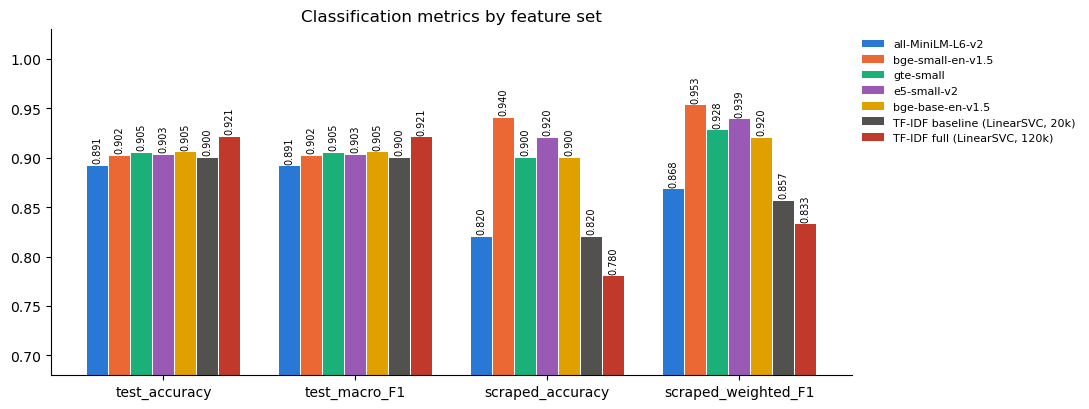

In [13]:
embeddings.plot_comparison(emb_table)

Best encoder: bge-base-en-v1.5
              precision    recall  f1-score   support

       World      0.923     0.895     0.909      1900
      Sports      0.959     0.982     0.971      1900
    Business      0.860     0.866     0.863      1900
    Sci/Tech      0.879     0.879     0.879      1900

    accuracy                          0.906      7600
   macro avg      0.905     0.906     0.905      7600
weighted avg      0.905     0.906     0.905      7600

              precision    recall  f1-score   support

       World      1.000     0.884     0.938        43
      Sports      0.333     1.000     0.500         1
    Business      0.000     0.000     0.000         0
    Sci/Tech      0.750     1.000     0.857         6

    accuracy                          0.900        50
   macro avg      0.521     0.721     0.574        50
weighted avg      0.957     0.900     0.920        50



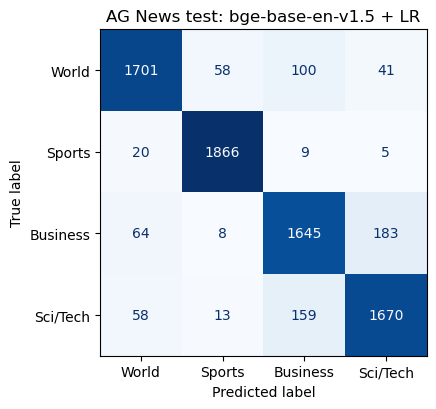

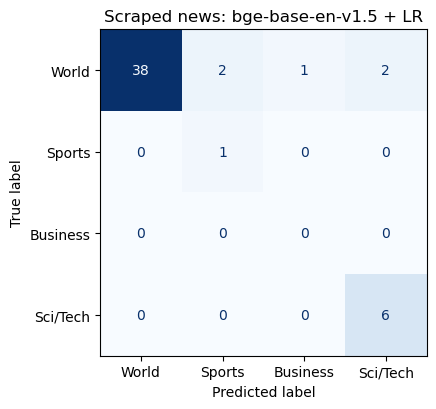

In [14]:
best_emb = emb_table.loc[list(config.CLASSIFICATION_MODELS), "test_macro_F1"].idxmax()
print("Best encoder:", best_emb)
classic.report(test["label"], emb_preds[best_emb]["test"], title=f"AG News test: {best_emb} + LR")
classic.report(scraped["label"], emb_preds[best_emb]["scraped"], title=f"Scraped news: {best_emb} + LR")

**Notes on the comparison**
- On AG News, all encoders score 0.89 to 0.91. Full TF-IDF (120k articles) is still best at 0.92.
- On the scraped news, the encoders win clearly: up to 0.94 (bge-small), against 0.78 to 0.82 for TF-IDF. They understand new names and topics that TF-IDF never saw in 2004 data.
- The bigger bge-base is not worth it: 3x the size and 3x the encoding time, for a very small gain.
- With only 50 scraped articles, one article is 2 points of accuracy, so small gaps there are noise.

### 4. How the chosen embedding is made
I chose **BGE** (bge-small-en-v1.5), from the Beijing Academy of AI (*C-Pack*, Xiao et al., 2023). It is trained in three steps:
1. **Pre-training (RetroMAE):** the model must rebuild a masked sentence from one summary vector, so that vector learns to hold the sentence's meaning.
2. **Contrastive training:** on a very large set of text pairs (title and body, question and answer), it learns to pull matching pairs together and push other texts apart.
3. **Fine-tuning:** on labelled data with hard negatives (texts that look similar but are wrong).

The output is one normalised 384-number vector per text. Texts are compared with cosine similarity.

## 2.4 Sentence Similarity (20)

1. Explore [embedding schemes](https://huggingface.co/spaces/mteb/leaderboard) best for **search** from the HuggingFace leader board.
2. Generate embeddings for news headlines using various encoders. Be conscious of the memory and size of these models and your compute limitations.
3. Take a few sample news articles. Visualize a heatmap of the correlation between headline embeddings.
4. Verify, using a few examples, that similar articles tend to get higher similarity scores.

### 1. Encoders chosen for search
From the MTEB leaderboard (English, Retrieval tab), small models again:

| Model | Query prefix | Document prefix | Notes |
|---|---|---|---|
| all-MiniLM-L6-v2 | none | none | general sentence similarity baseline |
| multi-qa-MiniLM-L6-cos-v1 | none | none | MiniLM tuned on 215M question-answer pairs for search |
| bge-small-en-v1.5 | `Represent this sentence for searching relevant passages: ` | none | strong small retrieval model |
| e5-small-v2 | `query: ` | `passage: ` | trained with query/passage prefixes |

### 2. Headline embeddings
The sample is 20 scraped headlines. Sixteen of them are 8 pairs where two outlets covered the same story (for example BBC and CBS on the French riots). The pairs sit next to each other in the plot, so a good model should show bright 2×2 blocks on the diagonal.

In [15]:
pairs = similarity.SAME_STORY_PAIRS
order = [i for p in pairs for i in p] + [3, 4, 46, 47]   # 8 pairs + 4 unrelated stories
titles = scraped["title"].tolist()
head_embs = {k: embeddings.encode(s["name"], titles, s["doc_prefix"]) for k, s in config.SEARCH_MODELS.items()}
pd.DataFrame({"#": range(1, len(order) + 1), "headline": [titles[i] for i in order]}).set_index("#")

,headline
#,
1,Curfew imposed in parts of central Paris and other cities after rioting across France
2,France's leaders vow to restore order after weekend of violent riots across the country
3,"Ukrainians dying because US restricting intelligence sharing, Zelensky adviser tells BBC"
4,"Zelenskyy says Russia hit Ukraine again with no ""warning from partners,"" U.S. delaying ""vital supplies"""
5,Shakahola cult leader Paul Mackenzie guilty of 191 murder charges in Kenya
6,Kenyan starvation cult leader guilty of murder of 190 children and one adult
7,Robert Kabera: Critic of Rwandan President Paul Kagame found beheaded in Uganda
8,Exiled critic of Rwandan president found beheaded in Uganda
9,US airman dies as daredevil descent goes wrong before Texas college football game


### 3. Heatmap of headline similarity

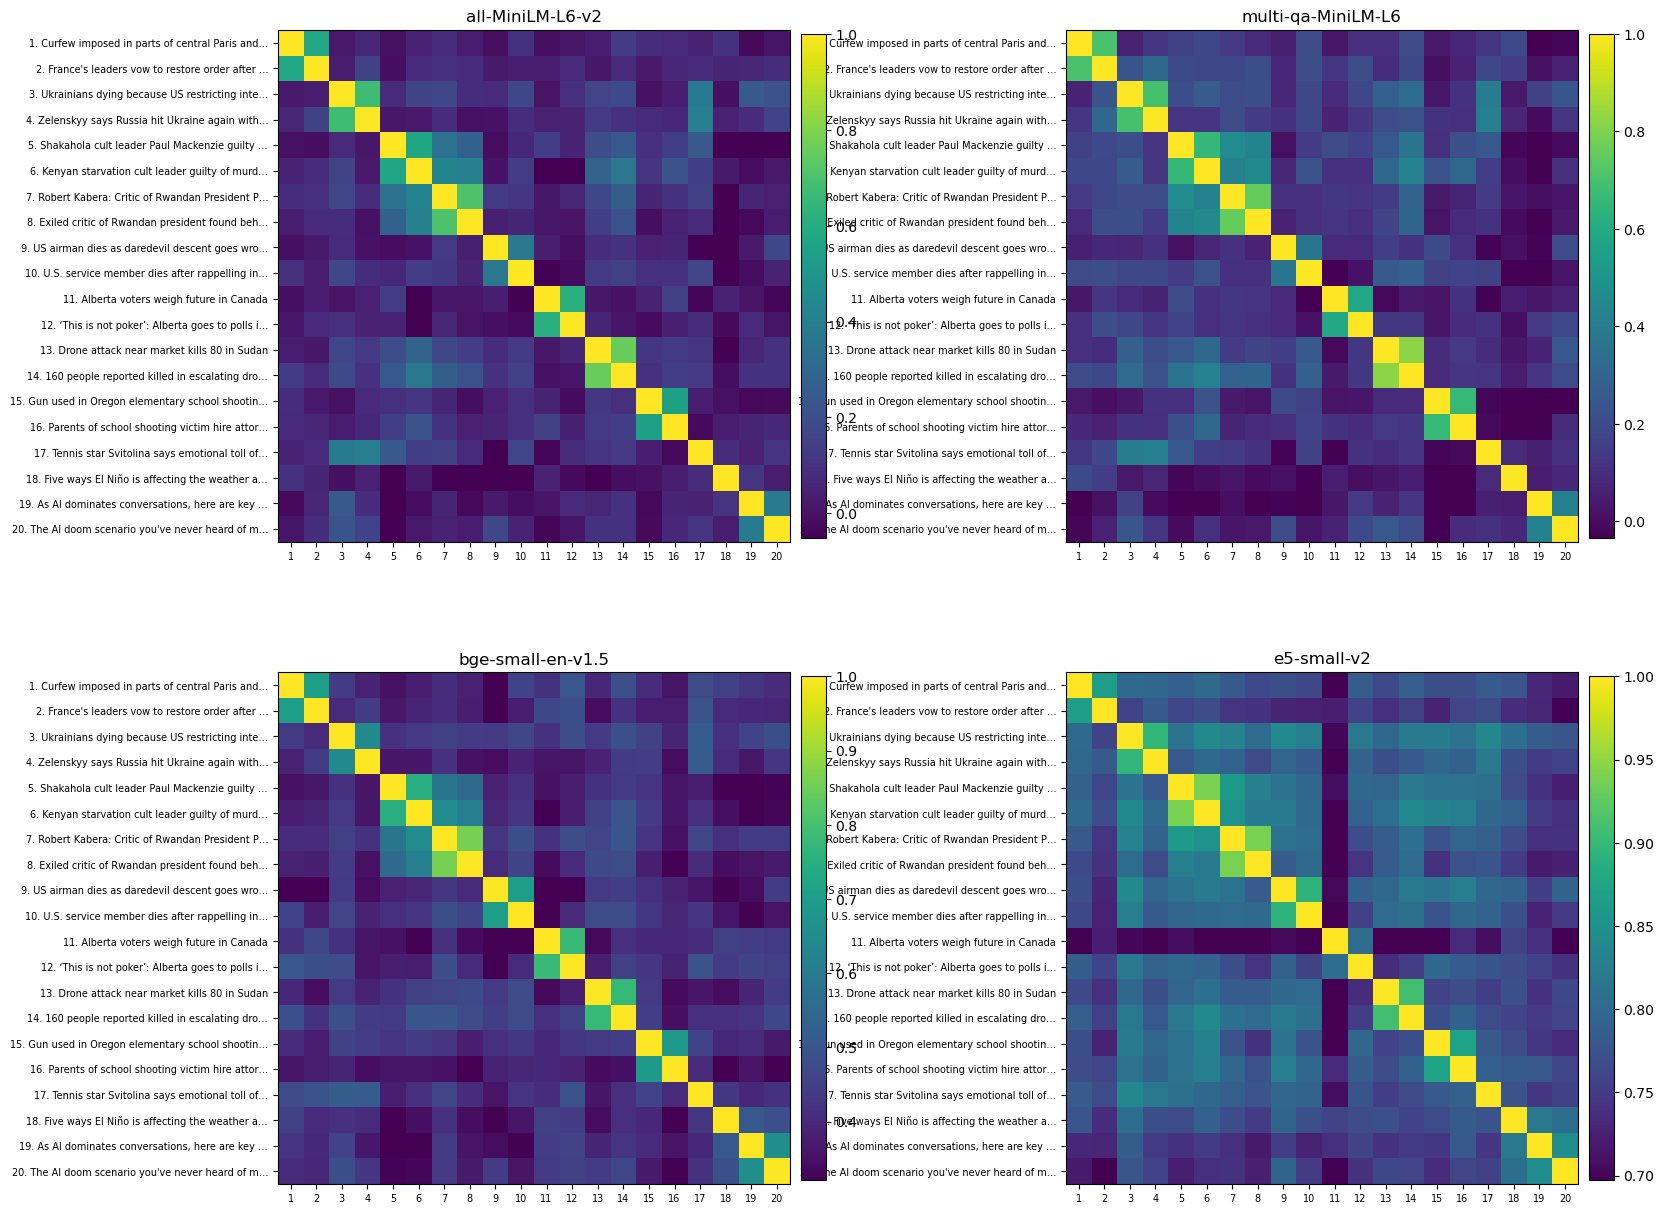

In [16]:
similarity.heatmaps(head_embs, titles, order)

### 4. Do similar articles score higher?
For each same-story pair: the cosine between the two headlines, the mean cosine of the first headline to the other 48, and the rank of its partner among all 49 neighbours (1 = nearest).

In [17]:
pair_tables = {k: similarity.pair_scores(E) for k, E in head_embs.items()}
summary = pd.DataFrame({k: {"mean pair cos": t["cos"].mean(), "mean cos to others": t["mean_cos_to_others"].mean(),
                            "pairs ranked #1": (t["partner_rank"] == 1).sum(), "mean partner rank": t["partner_rank"].mean()}
                        for k, t in pair_tables.items()}).T.round(3)
summary

,mean pair cos,mean cos to others,pairs ranked #1,mean partner rank
all-MiniLM-L6-v2,0.601,0.078,8.0,1.000
multi-qa-MiniLM-L6,0.655,0.131,7.0,1.125
bge-small-en-v1.5,0.737,0.412,8.0,1.000
e5-small-v2,0.891,0.772,8.0,1.000


In [18]:
detail = pair_tables[config.SEARCH_MODEL].copy()
detail.insert(0, "headline A", [titles[a] for a, _ in detail["pair"]])
detail.insert(1, "headline B", [titles[b] for _, b in detail["pair"]])
detail.drop(columns="pair").round(3)

,headline A,headline B,cos,mean_cos_to_others,partner_rank
0,Curfew imposed in parts of central Paris and other cities after rioting across France,France's leaders vow to restore order after weekend of violent riots across the country,0.698,0.422,1
1,"Ukrainians dying because US restricting intelligence sharing, Zelensky adviser tells BBC","Zelenskyy says Russia hit Ukraine again with no ""warning from partners,"" U.S. delaying ""vital supplies""",0.643,0.437,1
2,Shakahola cult leader Paul Mackenzie guilty of 191 murder charges in Kenya,Kenyan starvation cult leader guilty of murder of 190 children and one adult,0.749,0.393,1
3,Robert Kabera: Critic of Rwandan President Paul Kagame found beheaded in Uganda,Exiled critic of Rwandan president found beheaded in Uganda,0.861,0.440,1
4,US airman dies as daredevil descent goes wrong before Texas college football game,U.S. service member dies after rappelling incident at UT San Antonio football stadium,0.698,0.385,1
5,Alberta voters weigh future in Canada,"‘This is not poker’: Alberta goes to polls in referendum that has exposed divisions, not least among separatists",0.782,0.399,1
6,Drone attack near market kills 80 in Sudan,160 people reported killed in escalating drone attacks across Sudan,0.775,0.405,1
7,"Gun used in Oregon elementary school shooting was birthday gift from shooter's mom, sources say","Parents of school shooting victim hire attorneys to probe school plans, gun purchase",0.687,0.420,1


In [19]:
for idx in (0, 46):   # French riots, AI terms
    print(f"Query headline: {titles[idx]}")
    display(similarity.nearest_neighbours(head_embs[config.SEARCH_MODEL], titles, idx))

Query headline: Curfew imposed in parts of central Paris and other cities after rioting across France


,neighbour,cos
0,France's leaders vow to restore order after weekend of violent riots across the country,0.698
1,"Four people killed in ‘violent, fast-moving’ fire at Canadian military base",0.514
2,A Kelvin wave raised sea levels on the West Coast. More are coming,0.513


Query headline: As AI dominates conversations, here are key terms to know


,neighbour,cos
0,The AI doom scenario you've never heard of may be the hardest to stop,0.656
1,"Hilarious quips and ‘100,000-volt’ energy: the hypemen (and women) redefining Afrobeats music",0.553
2,The real reason it's going to take a while to know who won in some midterm races,0.530


**Do similar articles score higher? Yes.**
- In 31 of 32 checks, a headline's closest match is the same story from another outlet.
- Raw scores differ a lot between models (unrelated headlines score about 0.77 with e5 and 0.08 with MiniLM). Only the ranking, and the gap between related and unrelated pairs, can be compared.
- The heatmaps show bright 2×2 blocks for each pair, for every model.
- Limit: after the true match, unrelated headlines can still score fairly high (about 0.51), so a fixed cut-off would not work well.

## 2.5 - Advanced Search App (30)

Modify your Streamlit News Search application to use a local or cloud vector database.

1. Select embedding models and generate **quantized** embeddings to drive search.
2. Load the embeddings to the vector database (Qdrant, Weaviate, etc.)
3. Perform searches on some sentences and keywords
4. What metrics would evaluate search results and why.
5. Publish results of the search with pros and cons.

### Setup
- **Corpus:** the 7,600 AG News test articles plus the 50 scraped articles (7,650 total).
- **Model:** chosen below by a known-item test: each AG News **title** is a query, and the right answer is the article's own **description** among all 7,600 descriptions. This needs no hand labels and has one correct answer per query.
- **Vector database:** Qdrant in embedded mode (`QdrantClient(path=...)`), stored in `assignment2/qdrant_db/`. Docker is not needed.

In [20]:
ag_titles = test["title"].map(data.light_clean).tolist()
ag_descs = test["description"].map(data.light_clean).tolist()
ki_rows, ki_emb = [], {}
for k, s in config.SEARCH_MODELS.items():
    Q = embeddings.encode(s["name"], ag_titles, s["query_prefix"], cache_key="ki_titles")
    D = embeddings.encode(s["name"], ag_descs, s["doc_prefix"], cache_key="ki_descs")
    ki_emb[k] = (Q, D)
    ki_rows.append({"model": k, **vectordb.known_item_metrics(vectordb.search_float(Q, D, 10))})
pd.DataFrame(ki_rows).set_index("model").round(4)

,MRR@10,Recall@1,Recall@10
model,,,
all-MiniLM-L6-v2,0.6574,0.5684,0.8242
multi-qa-MiniLM-L6,0.6194,0.5293,0.7932
bge-small-en-v1.5,0.7295,0.6545,0.8637
e5-small-v2,0.7339,0.6575,0.8688


### 1. Quantized embeddings
Scalar (uint8) quantization maps each dimension's min-max range onto 0-255, so each number takes 1 byte instead of 4. Binary quantization keeps only the sign, so 384 dimensions fit in 48 bytes. The table compares them with float32 on the same known-item test.

In [21]:
Q, D = ki_emb[config.SEARCH_MODEL]
quant_table = vectordb.compare_quantization(Q, D)
quant_table

,bytes_per_vector,index_KB,MRR@10,Recall@1,Recall@10,overlap@10_vs_float,ms_per_query
precision,,,,,,,
float32,1536,11400.0,0.7295,0.6545,0.8637,1.0000,0.357
uint8 (scalar),384,2850.0,0.7278,0.6528,0.8626,0.9042,0.370
binary,48,356.2,0.6703,0.5917,0.8167,0.5037,0.700
binary + float rescore,48,356.2,0.7276,0.6547,0.8530,0.7797,0.787


### 2. Load the quantized embeddings into Qdrant
The collection stores uint8 vectors (`Datatype.UINT8`) with Euclidean distance. Euclidean distance is not affected by the 0-255 shift, so it ranks the same as on signed int8. Queries are quantized with the same per-dimension ranges, saved to `assignment2/cache/uint8_ranges.npy`.

In [22]:
spec = config.SEARCH_MODELS[config.SEARCH_MODEL]
corpus = pd.concat([
    pd.DataFrame({"title": ag_titles, "description": ag_descs, "category": test["label"].map(config.LABEL_NAMES),
                  "source": "AG News", "url": ""}),
    pd.DataFrame({"title": scraped["title"], "description": scraped["text_clean"].str[:400] + "…",
                  "category": scraped["label"].map(config.LABEL_NAMES), "source": scraped["source"],
                  "url": scraped["url"]}),
], ignore_index=True)
corpus_emb = embeddings.encode(spec["name"], (corpus["title"] + ". " + corpus["description"]).tolist(),
                               spec["doc_prefix"], cache_key="search_corpus")
client = vectordb.get_client()
n = vectordb.build_collection(client, corpus_emb, corpus.to_dict("records"))
print(f"{n:,} points in '{config.COLLECTION}' | vectors {corpus_emb.shape[1]}-dim uint8 | "
      f"{corpus_emb.nbytes/1024:.0f} KB as float32 -> {corpus_emb.nbytes/4/1024:.0f} KB as uint8")
print(client.get_collection(config.COLLECTION).config.params.vectors)

7,650 points in 'ag_news' | vectors 384-dim uint8 | 11475 KB as float32 -> 2869 KB as uint8
size=384 distance=<Distance.EUCLID: 'Euclid'> hnsw_config=None quantization_config=None on_disk=None memory=None datatype=<Datatype.UINT8: 'uint8'> multivector_config=None


### 3. Searches with sentences and keywords

In [23]:
model = embeddings.load_model(spec["name"])
encode_query = lambda q: model.encode(spec["query_prefix"] + q, normalize_embeddings=True)
cols = ["title", "category", "source", "distance"]
for q in ["riots and curfews in French cities", "drone strike kills civilians in Sudan",
          "risks of artificial intelligence", "oil prices", "Microsoft"]:
    print(f"\nQuery: {q}")
    display(vectordb.search(client, encode_query(q), k=5)[cols])


Query: riots and curfews in French cities


,title,category,source,distance
0,France's leaders vow to restore order after weekend of violent riots across the country,World,CBS News,511.5
1,Curfew imposed in parts of central Paris and other cities after rioting across France,World,BBC,533.2
2,Arson attack on Jewish centre in Paris (AFP),World,AG News,731.5
3,Haiti Moves on Pro-Aristide Militants,World,AG News,748.7
4,French Troops Clash with Ivory Coast Protesters,World,AG News,750.9



Query: drone strike kills civilians in Sudan


,title,category,source,distance
0,160 people reported killed in escalating drone attacks across Sudan,World,Al Jazeera,559.3
1,Drone attack near market kills 80 in Sudan,World,Guardian,604.7
2,Landmine kills Darfur aid workers,World,AG News,701.1
3,Two Aid Workers Killed in Attack on Darfur Aid Convoy,World,AG News,715.8
4,Inaction s Consequence,World,AG News,720.3



Query: risks of artificial intelligence


,title,category,source,distance
0,The AI doom scenario you've never heard of may be the hardest to stop,Sci/Tech,CBS News,763.4
1,"As AI dominates conversations, here are key terms to know",Sci/Tech,CBS News,778.2
2,Static over RFID,Sci/Tech,AG News,797.7
3,Study: Mobile phone use increases brain tumor risk,Sci/Tech,AG News,797.9
4,Self-sustaining killer robot creates a stink,Sci/Tech,AG News,798.5



Query: oil prices


,title,category,source,distance
0,Oil Retreats on Signs Economy Hurting,Business,AG News,571.6
1,Oil price down as Iraq fears ease,Business,AG News,584.1
2,Oil prices look set to dominate,Business,AG News,588.2
3,Oil prices surge to a new high,Business,AG News,596.6
4,"Oil Hits $53 on Winter Worries, Nigeria",Business,AG News,598.6



Query: Microsoft


,title,category,source,distance
0,Getting with the program,Sci/Tech,AG News,658.1
1,Is Google the new devil?,Sci/Tech,AG News,673.2
2,Microsoft launches new search engine,Sci/Tech,AG News,681.0
3,Minding the Search Engine Business,Sci/Tech,AG News,698.1
4,Microsoft to showcase new MSN Search preview,Sci/Tech,AG News,698.6


In [24]:
print("Filtered: 'election' in scraped news only (source = Guardian)")
display(vectordb.search(client, encode_query("election"), k=5, source="Guardian")[cols])
print("Filtered: 'merger' in Business only")
display(vectordb.search(client, encode_query("merger"), k=5, category="Business")[cols])

Filtered: 'election' in scraped news only (source = Guardian)


,title,category,source,distance
0,"‘This is not poker’: Alberta goes to polls in referendum that has exposed divisions, not least among separatists",World,Guardian,839.7
1,"‘4,000 people minding our own business’: four decades on, Falklands again face a hostile Argentina",World,Guardian,895.7
2,Hurricane Trudy menaces Mexico’s Pacific coast and Greece hit by deadly floods,World,Guardian,908.9
3,"Hilarious quips and ‘100,000-volt’ energy: the hypemen (and women) redefining Afrobeats music",World,Guardian,918.4
4,US grants deportation reprieve to migrants from Ukraine and Sudan,World,Guardian,921.7


Filtered: 'merger' in Business only


,title,category,source,distance
0,Q &A : Merger changes little for now,Business,AG News,694.1
1,INTERVIEW: Australia s QBE Consolidates European Units,Business,AG News,714.6
2,Sears and Kmart Agree to Merge in $11 Billion Deal,Business,AG News,721.3
3,Oracle in Merger Talks with Other Firms,Business,AG News,726.4
4,"Sprint, Nextel to Combine",Business,AG News,734.6


### 4. Metrics for search results
Two labelled tests are used here. The known-item test (above) gives MRR@10 and Recall@k. The test below gives category precision: P@10 is the share of the top 10 results in the category the query is about. Latency is measured through Qdrant.

In [25]:
cat_queries = [
    ("oil prices rise as OPEC cuts output", "Business"), ("stock market falls on inflation fears", "Business"),
    ("quarterly earnings beat expectations", "Business"), ("merger", "Business"),
    ("team wins championship in overtime", "Sports"), ("Olympic gold medal sprinter", "Sports"),
    ("Yankees", "Sports"), ("injured quarterback", "Sports"),
    ("new smartphone chip released", "Sci/Tech"), ("NASA launches mission to Mars", "Sci/Tech"),
    ("Linux", "Sci/Tech"), ("computer virus spreads by email", "Sci/Tech"),
    ("peace talks after border clashes", "World"), ("election results contested by opposition", "World"),
    ("Iraq", "World"), ("suicide bombing kills dozens", "World"),
]
cat_table = vectordb.category_precision(client, encode_query, cat_queries)
print(f"mean P@10 = {cat_table['P@10'].mean():.3f} | median latency = {cat_table['latency_ms'].median():.1f} ms")
cat_table

mean P@10 = 0.919 | median latency = 25.4 ms


,query,intended,P@10,top_result,latency_ms
0,oil prices rise as OPEC cuts output,Business,1.0,OPEC Increases Oil Output,44.3
1,stock market falls on inflation fears,Business,0.7,Stocks Open Lower; Inflation Data Weighs,17.7
2,quarterly earnings beat expectations,Business,0.9,Peoplesoft Revenues To Beat Expectations (NewsFactor),30.5
3,merger,Business,0.8,Q &A : Merger changes little for now,21.2
4,team wins championship in overtime,Sports,1.0,"49ers get first W, but lose Peterson for year",48.3
5,Olympic gold medal sprinter,Sports,0.9,Phelps Eyes Fourth Gold,29.9
6,Yankees,Sports,1.0,Damned Yankees Send New Yorkers into Mourning,22.2
7,injured quarterback,Sports,1.0,Bills' Williams Sustains Neck Injury (AP),23.0
8,new smartphone chip released,Sci/Tech,0.7,Atheros reaches into electronics devices,25.4
9,NASA launches mission to Mars,Sci/Tech,1.0,Nasa to resume shuttle missions,25.6


**Which metrics, and why**
- **MRR@10 / Recall@10:** how high the one correct article ranks. Good when each query has one right answer.
- **Precision@10:** how many of the first 10 results are on topic. Users mostly read only the first page.
- **nDCG@10:** the standard metric when results are graded (very / somewhat / not relevant). Not used here, as I have no graded labels.
- **Overlap with float32:** how much quantization changes the results.
- **Speed and size:** whether the system is cheap to run at scale.

### 5. Results, pros and cons
**Results**
- bge-small and e5-small search best (MRR@10 about 0.73). I used bge-small.
- uint8 vectors are 4x smaller with almost no loss (MRR 0.730 → 0.728). Binary vectors are 32x smaller but worse (0.67) unless rescored.
- 92% of top-10 results are in the right category, for both sentences and keywords.
- A search takes about 25 ms.

**Pros**
- Finds articles by meaning, not just matching words.
- Works for short keyword queries too.
- Small quantized index, and filters by category and source.
- No server needed.

**Cons**
- Can miss exact keywords (the top result for "Microsoft" does not mention Microsoft). Mixing in keyword search (BM25) would help.
- Always returns k results, even when few are relevant.
- Embedded Qdrant allows only one process at a time; a real system needs the Qdrant server.
- Long articles must be cut to fit the model's 512-token limit.

### Streamlit app
The notebook must release the Qdrant folder first (embedded mode allows one process at a time). Then run, from the `NLP` folder:
```bash
conda activate ml_hw
streamlit run assignment2/search_app.py
```
The app has a search box and filters for result count, category and source.

_TODO: add a screenshot of the app here._

In [26]:
client.close()   # release assignment2/qdrant_db for the Streamlit app